In [ ]:
from engine.utils import l2_normalise, get_rabit
from engine.rabitq import get_rabit
from engine.evp import get_evp_row_arg_partition_stable, get_evp_ternary_row_mask

from move import move_on_unit_sphere

import numpy as np

In [61]:
def get_next_normed_random_vec( d: int ) -> np.array:
    """
    :param d: the number of dimensions required
    :return: a l2 normed random vector of dimension d and
    """
    return l2_normalise(np.random.normal(0, 1, (d,)))


In [62]:
from move import move_on_unit_sphere, get_orthogonal_vector

BOTH = 4
EVP = 3
RABIT = 2
NEITHER = 1

def move_and_test(vector: np.array, angle: float) -> int:
    """
    :param vector: a l2 normed vector
    :param angle: the angle to move
    :return: One of BOTH, EVP, RABIT or NIETHER depending on what nodes have changed by the rotation.
    """
    old_evp = get_evp_row_arg_partition_stable(vector)  # or get_evp_row_arg_partition_stable or get_evp_ternary_row_mask
    old_rabit = get_rabit(vector)
    evp_diff = False
    rabit_diff = False

    direction = get_orthogonal_vector(vector)
    vector = move_on_unit_sphere(vector, direction, angle)  # Generate the moved vector

    evp = get_evp_row_arg_partition_stable(vector) # or get_evp_row_arg_partition_stable or get_evp_ternary_row_mask
    rabit = get_rabit(vector)

    if not np.array_equal(old_evp, evp):
        evp_diff = True

    if not np.array_equal(old_rabit, rabit):
        rabit_diff = True

    if evp_diff and rabit_diff:
        return BOTH
    elif evp_diff:
        return EVP
    elif rabit_diff:
        return RABIT
    else:
        return NEITHER

In [63]:
from tqdm import tqdm

In [64]:
both_count = 0
evp_count = 0
rabit_count = 0
neither_count = 0

dimension = 10
angle = 0.1
iters = 500 #0
for i in tqdm(range(iters)):
    vector = get_next_normed_random_vec(dimension)
    result = move_and_test(vector, angle)
    if result == EVP:
        evp_count += 1
    elif result == RABIT:
        rabit_count += 1
    elif result == NEITHER:
        neither_count += 1
    else:
        both_count += 1



100%|██████████| 500/500 [00:00<00:00, 12329.88it/s]


In [65]:
print(f"Iterations: {iters} Dimension: {dimension} Angle: {angle}")
print(f"% changed through angle:")
print(f"Both {both_count * 100/iters}%")
print(f"EVP {evp_count * 100/iters}%")
print(f"RABIT {rabit_count * 100/iters}%")
print(f"NEITHER {neither_count * 100/iters}%")


Iterations: 500 Dimension: 10 Angle: 0.1
% changed through angle:
Both 9.8%
EVP 6.6%
RABIT 36.0%
NEITHER 47.6%


In [66]:
angle = 0.0001
iters = 1000

def run_experiment(dimension: int) -> tuple[int, int, int, int]:
    both_count = 0
    evp_count = 0
    rabit_count = 0
    neither_count = 0

    for i in range(iters):
        vector = get_next_normed_random_vec(dimension)
        result = move_and_test(vector, angle)
        if result == EVP:
            evp_count += 1
        elif result == RABIT:
            rabit_count += 1
        elif result == NEITHER:
            neither_count += 1
        else:
            both_count += 1

    return both_count,evp_count,rabit_count,neither_count


In [67]:
import pandas as pd
import matplotlib.pyplot as plt

In [84]:
dimension = 2
xticks = []
results = []

while dimension < 2050:
    xticks.append(dimension)
    both_count,evp_count,rabit_count,neither_count = run_experiment(dimension)
    res = {"Dimensions": dimension, "both_count": both_count, "evp_count": evp_count, "rabit_count": rabit_count,"neither_count":neither_count}
    results.append(res)
    dimension = dimension *2



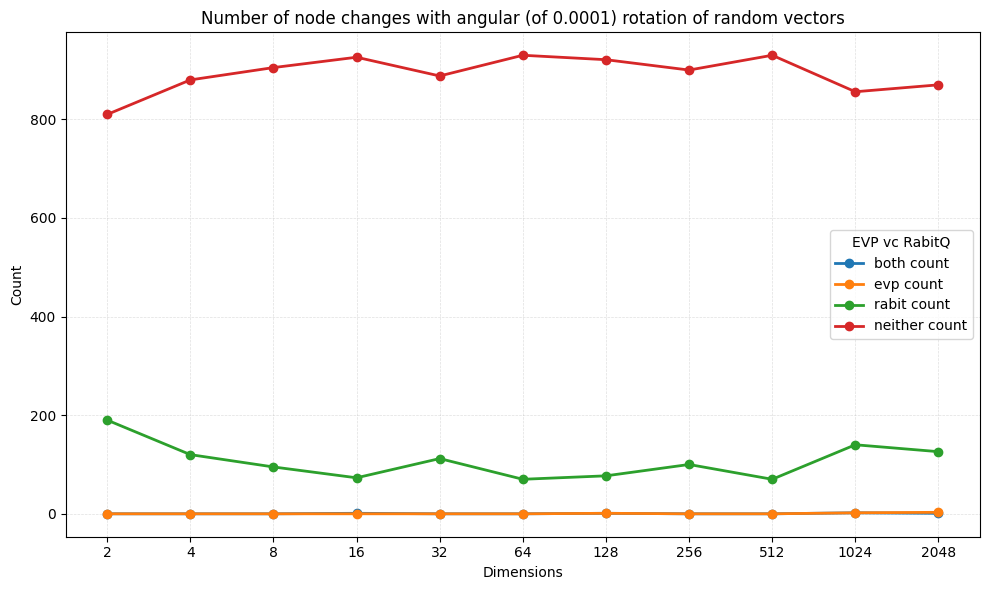

In [85]:
df = pd.DataFrame(results)

# Define your dimensions and data
count_columns = ['both_count', 'evp_count', 'rabit_count', 'neither_count']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']  # Distinct colours

plt.figure(figsize=(10, 6))

for i, column in enumerate(count_columns):
    if column in df.columns:
        plt.plot(df.index, df[column],
                 label=column.replace('_', ' '),
                 color=colors[i % len(colors)],
                 marker='o',
                 linewidth=2)

plt.title(f'Number of node changes with angular (of {angle}) rotation of random vectors')
plt.xlabel('Dimensions')
plt.ylabel('Count')
plt.xticks(df.index, xticks)
plt.legend(title='EVP vc RabitQ')
plt.grid(True, which='both', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

In [86]:
 output_path = "fixed_angle.csv"
 df.to_csv(output_path, mode='w')